<a href="https://colab.research.google.com/github/piihutanoch/pet-breed-classifier/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
project_dir= Path('/content/drive/MyDrive/pet-breed-classifier')
artifacts_dir= project_dir/"artifacts"
data_dir= Path('/content/data')

artifacts_dir.mkdir(parents=True, exist_ok= True)
data_dir.mkdir(parents=True, exist_ok= True)

seed= 42
print('artifacts will be saved into: ', artifacts_dir)

artifacts will be saved into:  /content/drive/MyDrive/pet-breed-classifier/artifacts


In [3]:
!wget -q --show-progress https://s3.amazonaws.com/fast-ai-imageclas/oxford-iiit-pet.tgz -O /content/pets.tgz
!tar -xzf /content/pets.tgz -C {data_dir}
!ls {data_dir}/oxford-iiit-pet

/content/pets.tgz   100%[===================>] 774.10M  61.5MB/s    in 13s     
annotations  images


In [4]:
from torchvision.datasets import OxfordIIITPet

#root= data_dir is where the data is downloaded
#target_types='category' gives us breed the breed label associated with the image
trainval_ds= OxfordIIITPet(root= data_dir, split='trainval', target_types='category', download= True)

test_ds= OxfordIIITPet(root= data_dir, split='test', target_types='category', download= True)

print("trainval size:", len(trainval_ds))
print("test size:", len(test_ds))
print("number of breeds:", len(trainval_ds.classes))

trainval size: 3680
test size: 3669
number of breeds: 37


The dataset is loaded using torchvision.datasets.OxfordIIITPet. The training/validation and test splits are loaded separately, with target_types='category' to retrieve the breed label for each image.

<class 'tuple'>
<class 'PIL.Image.Image'> (394, 500) RGB
label: 0 → breed: Abyssinian


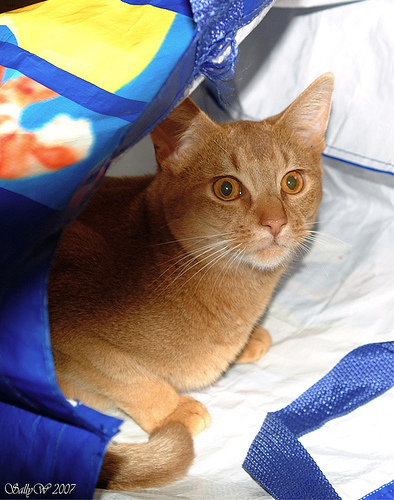

In [5]:
sample= trainval_ds[0] # the sample has a tuple containing an image and corresponding label
print(type(sample))

# Each sample contains an image and its corresponding breed label
img, label= sample #tuple unpacking

print(type(img), img.size, img.mode)

# Convert the numerical label into its corresponding breed name
print("label:", label, "→ breed:", trainval_ds.classes[label])
img

### Inspecting a Dataset Sample

Before proceeding with preprocessing, I inspected an individual sample to understand how the dataset is structured.

Each sample is returned as a tuple containing a PIL image and its corresponding numerical label. The image is stored in RGB format, with dimensions(in pixels) that can vary across samples.

The numerical label represents the breed category and can be mapped back to its name using the dataset's `classes` attribute.

This gives us a better understanding of the input format and target labels before preparing the data for the model.

In [6]:
import pandas as pd

# Get the breed names corresponding to the numerical labels
classes= trainval_ds.classes

# Create a DataFrame containing image paths and their labels
df= pd.DataFrame({
    'path': [str(p) for p in trainval_ds._images],
    'label': trainval_ds._labels
})

# Map numerical labels to their corresponding breed names
df['breed']= [classes[lbl] for lbl in df['label']]

# Identify the species using the filename naming convention
def get_species(path):
  filename= Path(path).name
  first_letter= filename[0]
  if first_letter.isupper():
    return 'cat'
  else:
    return 'dog'

# Add a species column to distinguish between cats and dogs
df["species"] = df["path"].apply(get_species)
df.head()

,path,label,breed,species
0,/content/data/oxford-iiit-pet/images/Abyssinia...,0,Abyssinian,cat
1,/content/data/oxford-iiit-pet/images/Abyssinia...,0,Abyssinian,cat
2,/content/data/oxford-iiit-pet/images/Abyssinia...,0,Abyssinian,cat
3,/content/data/oxford-iiit-pet/images/Abyssinia...,0,Abyssinian,cat
4,/content/data/oxford-iiit-pet/images/Abyssinia...,0,Abyssinian,cat


##Creating a Dataset DataFrame

A Pandas DataFrame is created to organise the image paths and their corresponding numerical labels.

The numerical labels are mapped to their respective breed names using the dataset's class list. An additional species column distinguishes between cats and dogs.

Species identification is based on the filename convention followed by the Oxford-IIIT Pet dataset, where cat filenames begin with an uppercase letter and dog filenames begin with a lowercase letter.

This structured representation makes the dataset easier to inspect, filter and analyse.

In [17]:
import json

# Map numerical class indices to breed names
idx_to_class= {i: name for i, name in enumerate(classes)}

# Save the class mapping for later use
with open(artifacts_dir/"classes.json", "w") as f:
    json.dump(idx_to_class, f, indent=2)

# Map each breed to its corresponding species
breed_species= dict(zip(df["breed"], df["species"]))

# Save the breed-to-species mapping
with open(artifacts_dir/"breed_species.json", "w") as f:
    json.dump(breed_species, f, indent=2)

print(len(idx_to_class), "classes saved;", len(breed_species), "breeds mapped")


37 classes saved; 37 breeds mapped


### Saving Class and Species Mappings

Two dictionaries are created to store the class information required by the project.

The first dictionary maps numerical class indices to their corresponding breed names, while the second maps each breed to its species (cat or dog).

Both mappings are saved as JSON files in the artifacts directory. These files can be reused during model evaluation and inference to convert numerical predictions into readable labels and identify the corresponding species.

In [18]:
from sklearn.model_selection import train_test_split

# Generate an index for every sample in the dataset
all_idx= list(range(len(trainval_ds)))

# Split the indices into training and validation subsets
train_idx, val_idx= train_test_split(
    all_idx,
    test_size=0.15,
    stratify=df["label"],
    random_state=seed
)

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))


Training samples: 3128
Validation samples: 552


### Creating Training and Validation Splits

A 15% validation split is used, with stratification based on the numerical breed labels to maintain approximately consistent class distributions across both subsets.

The random state is fixed to ensure reproducibility. The resulting split contains 3,128 training samples and 552 validation samples. The separate test set remains untouched for final model evaluation.

In [19]:
# Store the seed and dataset indices for reproducibility
splits= {
    "seed": seed,
    "train": train_idx,
    "val": val_idx
}

# Save the split information for reuse
with open(artifacts_dir / "splits.json", "w") as f:
    json.dump(splits, f)

print("Saved splits.json")

Saved splits.json


### Saving Dataset Splits

The training and validation indices, along with the random seed, are saved in a JSON file. This allows the same data split to be reproduced and reused across different stages of the project.

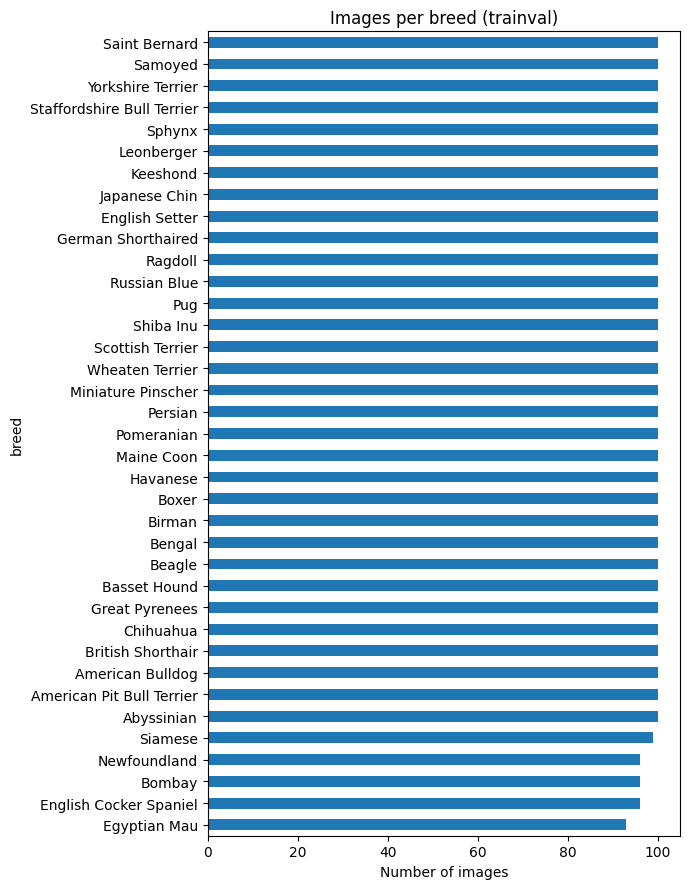

min: 93  max: 100


In [10]:
import matplotlib.pyplot as plt

counts= df['breed'].value_counts()

counts.sort_values().plot(kind='barh', figsize=(7, 9))
plt.xlabel("Number of images")
plt.title("Images per breed (trainval)")
plt.tight_layout()
plt.show()
print("min:", counts.min(), " max:", counts.max())

The dataset contains between 93 and 100 images per breed, indicating a fairly uniform class distribution. No significant class imbalance is observed, so additional balancing techniques are not required based on the current distribution.

In [12]:
df["species"].value_counts()

,count
species,
dog,2492
cat,1188


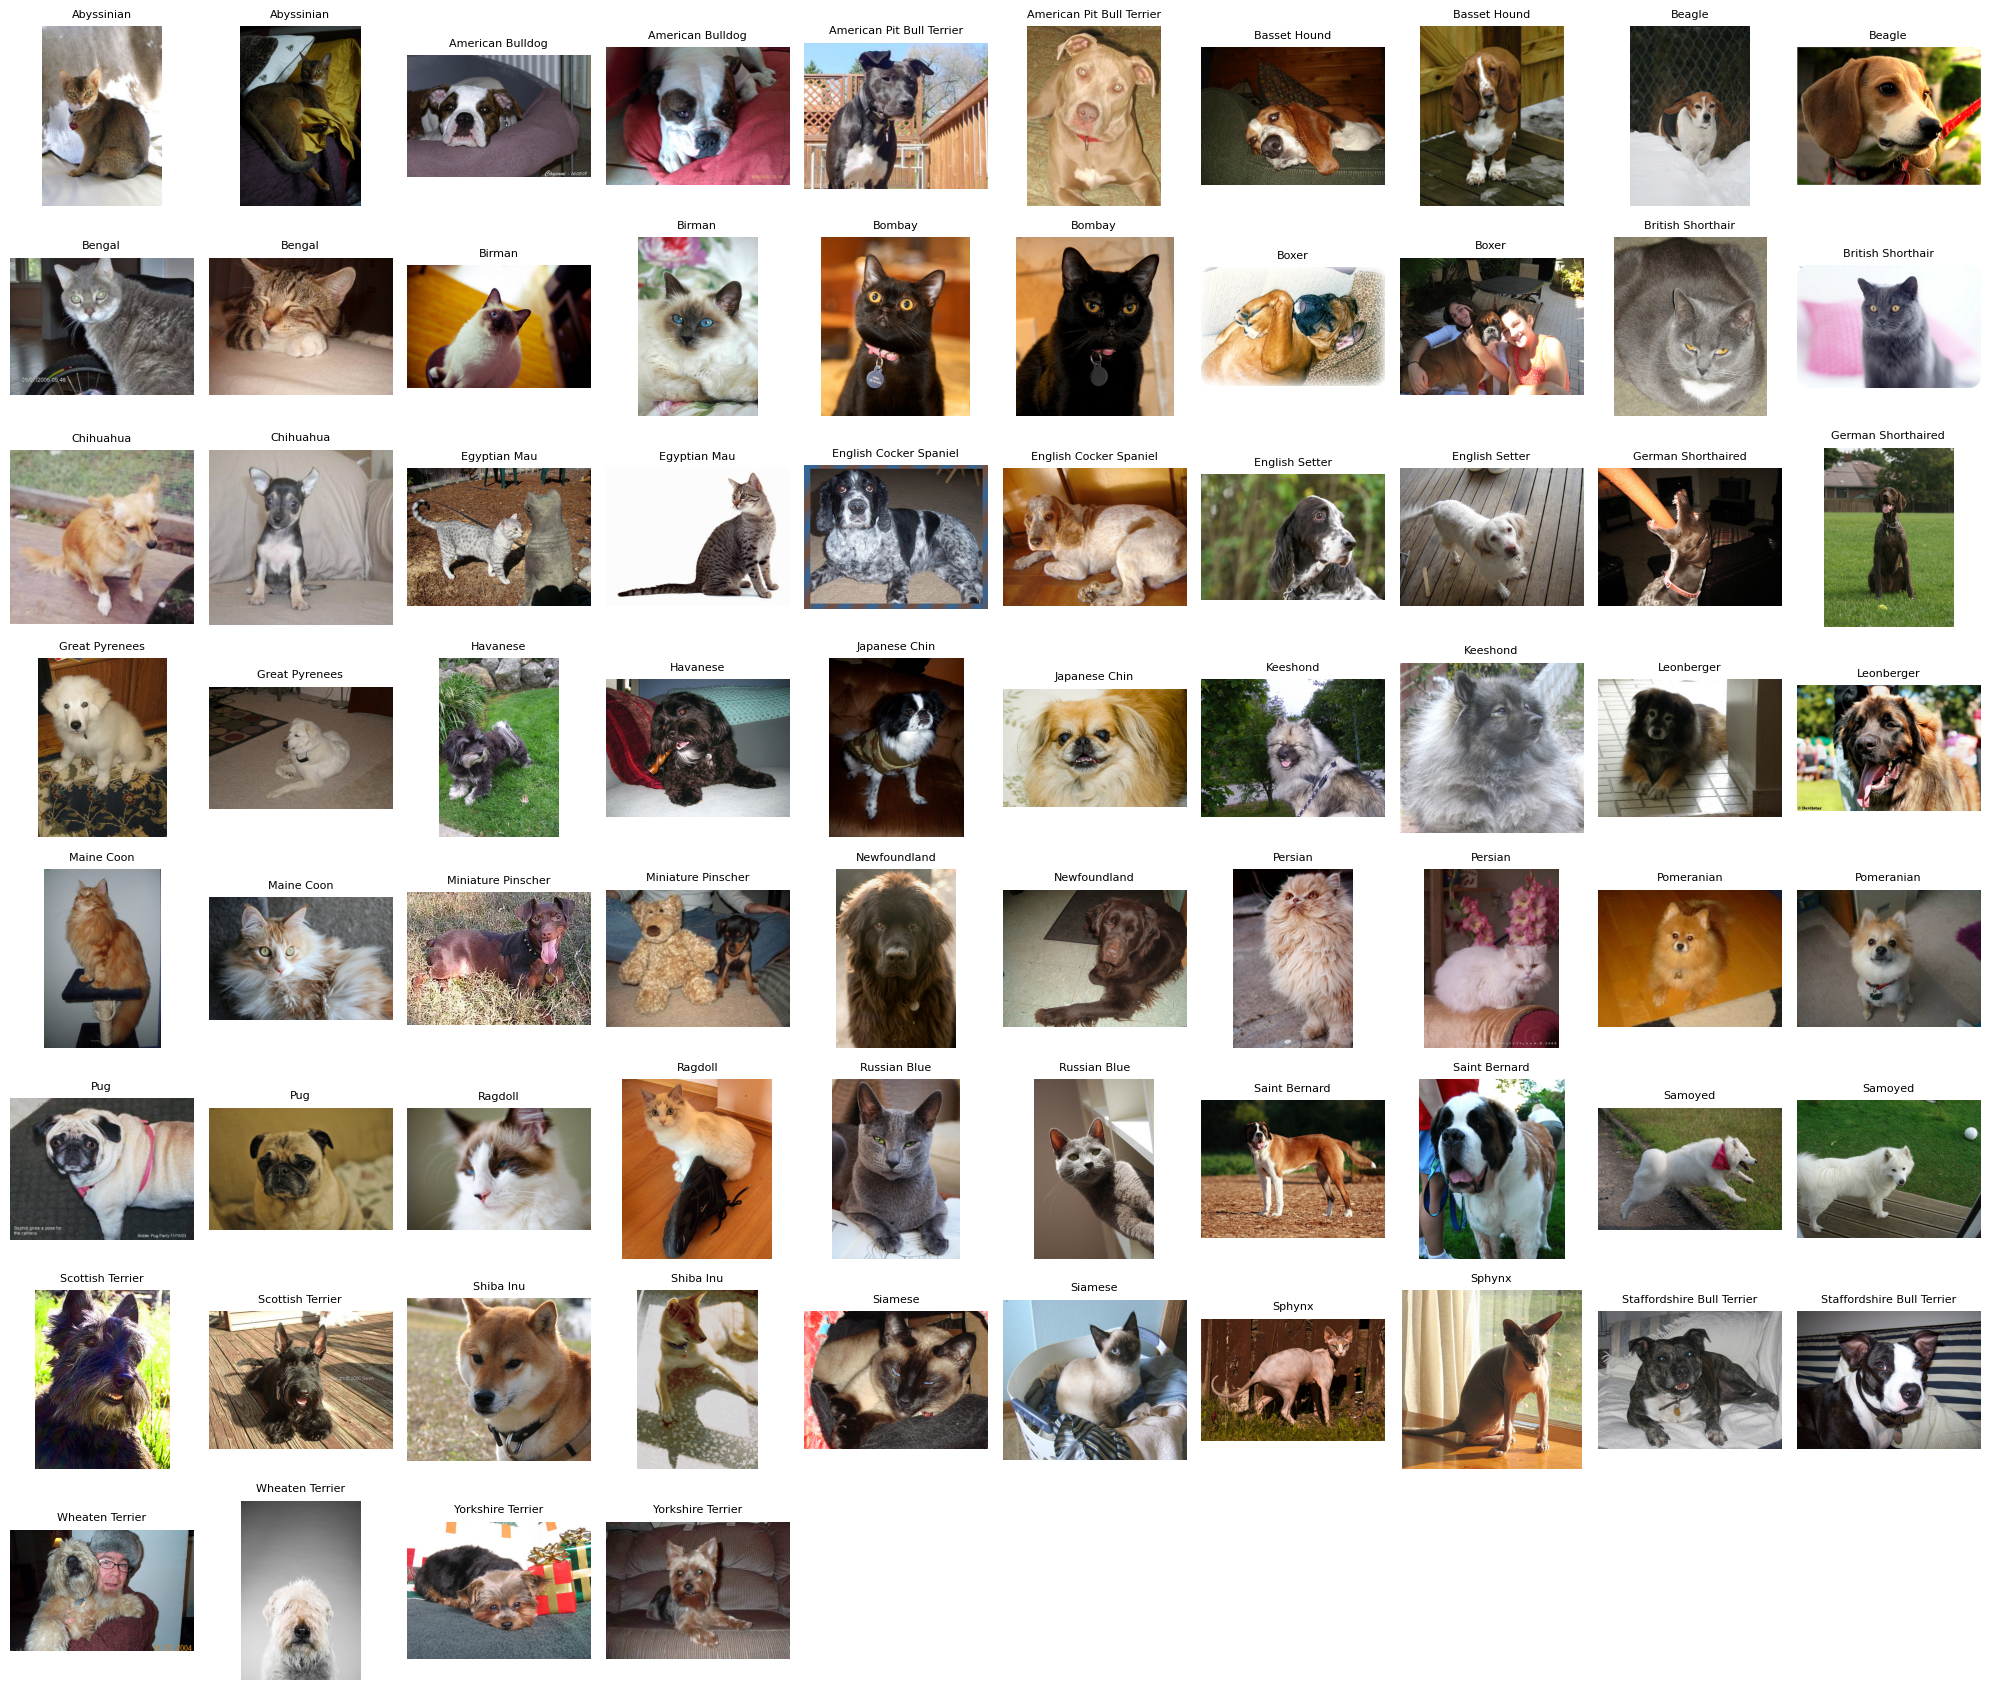

In [22]:
from PIL import Image

fig, axes = plt.subplots(8, 10, figsize=(20, 17))
axes = axes.flatten()
#plt.subplots(8, 10) creates a grid of 8 rows and 10 columns (80 plots).
#axes.flatten() converts the 2D array of subplot axes into a 1D array.

slot = 0
for breed in classes:
    breed_rows = df[df["breed"] == breed].sample(2, random_state= seed) #random_state ensures that the same images are shown everytime
    for path in breed_rows["path"]:
        img = Image.open(path).convert("RGB")
        axes[slot].imshow(img)
        axes[slot].set_title(breed, fontsize=8)
        slot += 1

for ax in axes:
    ax.axis("off") #axis("off") hides axis markings and borders.

plt.tight_layout()
plt.show()

In [23]:
sizes= []
for path in df["path"].sample(200, random_state=seed):
    img= Image.open(path)
    w, h= img.size
    sizes.append((w, h))

size_df= pd.DataFrame(sizes, columns=["width", "height"])
size_df.describe()

,width,height
count,200.000000,200.000000
mean,419.395000,387.400000
std,119.671279,137.888492
min,133.000000,112.000000
25%,333.000000,332.000000
50%,459.000000,375.000000
75%,500.000000,500.000000
max,1138.000000,1734.000000


In [25]:
import torch
from torch.utils.data import Subset, DataLoader
from torchvision import transforms

# Resize images and convert them into PyTorch tensors
tfm= transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# Load the dataset with the defined transformations
train_base= OxfordIIITPet(
    root=data_dir,
    split="trainval",
    target_types="category",
    transform=tfm
)

# Select only the training samples using the saved indices
train_subset= Subset(train_base, train_idx)

# Load training data in batches of 32
loader= DataLoader(
    train_subset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

# Inspect the first batch
images, labels= next(iter(loader))

print("images:", images.shape)
print("labels:", labels.shape)
print("first 5 breeds:", [classes[i] for i in labels[:5]])


images: torch.Size([32, 3, 224, 224])
labels: torch.Size([32])
first 5 breeds: ['Havanese', 'Persian', 'American Bulldog', 'Siamese', 'Chihuahua']


### Image Preprocessing and Data Loading

The images are preprocessed using `torchvision.transforms` before being passed to the CNN.

- **Resize((224, 224)):** Resizes all images to a fixed resolution so they have consistent dimensions and can be processed in batches.
- **ToTensor():** Converts PIL images into PyTorch tensors, changes the dimension order to `(C, H, W)` and scales pixel values from 0–255 to 0–1.

The `Subset` class selects the training samples using the previously generated `train_idx` indices, keeping the validation samples separate.

A PyTorch `DataLoader` is then created with:
- `batch_size=32`: Loads 32 images per batch.
- `shuffle=True`: Randomises the sample order during each training iteration.
- `num_workers=2`: Uses two worker processes for parallel data loading.

The first batch is retrieved to verify the preprocessing pipeline. Its shape is `[32, 3, 224, 224]`, representing 32 RGB images of size 224 × 224, with one numerical label per image.

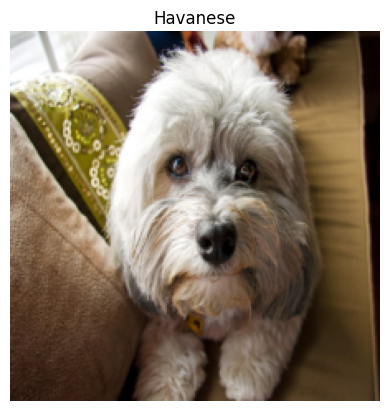

In [27]:
# Select the first image from the batch of 32
first= images[0]

# Rearrange dimensions from (C, H, W) to (H, W, C) for display
plt.imshow(first.permute(1, 2, 0))

# Display the corresponding breed name
plt.title(classes[labels[0]])
plt.axis("off")
plt.show()


### Visualising a Preprocessed Image

The first image from the training batch is displayed to verify the preprocessing pipeline. Since PyTorch stores images in `(C, H, W)` format while Matplotlib expects `(H, W, C)`, `permute()` rearranges the dimensions before visualisation. The corresponding breed name is displayed using its numerical label.